# FRB Data Augmentation Pipeline v6

**Fix from v5:** Model was learning texture difference (FRB patches = mostly empty, noise = structured).

**Solution:** Inject FRB sweeps onto real noise backgrounds. Both classes now have the same
noise texture — the only difference is whether a diagonal dispersive sweep is present.

**Pipeline:**
1. Load → downsample time → crop to live channels
2. Extract noise patches (burst-free regions)
3. Extract dedispersed burst signal (burst region minus background)
4. Redisperse burst at target DM
5. **Add redispersed burst onto a random noise patch**
6. Resample, normalize → LSTM-ready

**Output:** `(batch, 256, 256)` where FRB = noise + sweep, Noise = noise only

In [1]:
import numpy as np
import h5py
import os
import glob
import json
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

FRB_H5_DIR    = "./realtime_data/FRBs/"
DM_CATALOG    = "./dm_catalog.json"
OUTPUT_DIR    = "./augmented_dataset/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

with open(DM_CATALOG, 'r') as f:
    dm_catalog = json.load(f)

print(f"DM catalog: {len(dm_catalog)} files")

DM catalog: 30 files


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================
CHIME_FREQ_LOW   = 400.0
CHIME_FREQ_HIGH  = 800.0
NATIVE_TIME_RES  = 2.56e-6
K_DM             = 4.148808e3

TIME_DOWNSAMPLE  = 256
EFFECTIVE_TIME_RES = NATIVE_TIME_RES * TIME_DOWNSAMPLE

PATCH_TIME_BINS  = 256
TARGET_FREQ_BINS = 256

N_DM_AUGMENTS    = 30
DM_AUG_RANGE     = (100, 2500)
N_TEMPORAL_SHIFTS = 8
BURST_EXCLUSION_FACTOR = 3.0

# Noise injection: controls how bright the burst is relative to noise
# SNR_INJECT_RANGE = (low, high) — random SNR multiplier per sample
# Higher = easier to detect. Start broad, narrow later.
SNR_INJECT_RANGE = (0.5, 5.0)

MIN_BURST_SNR    = 3.0
NAN_THRESHOLD    = 0.3
LIVE_CHANNEL_THRESHOLD = 0.5

SEED = 42
rng = np.random.RandomState(SEED)

print(f"Effective time resolution: {EFFECTIVE_TIME_RES*1000:.3f} ms")
print(f"Patch duration:            {PATCH_TIME_BINS * EFFECTIVE_TIME_RES * 1000:.1f} ms")
print(f"SNR injection range:       {SNR_INJECT_RANGE}")

Effective time resolution: 0.655 ms
Patch duration:            167.8 ms
SNR injection range:       (0.5, 5.0)


## 1. Load, Downsample, Discover Live Channels

In [3]:
def load_spectrogram(fpath, power_key, beam_idx=0):
    with h5py.File(fpath, 'r') as f:
        ds = f[power_key]
        if ds.ndim == 3:
            power = ds[:, beam_idx, :].T
        elif ds.ndim == 2:
            power = ds[()]
            if power.shape[1] > power.shape[0]:
                power = power.T
        else:
            raise ValueError(f"Unexpected ndim={ds.ndim}")
    return power.astype(np.float32)


def downsample_time(power_2d, factor):
    n_time, n_freq = power_2d.shape
    n_trim = (n_time // factor) * factor
    trimmed = power_2d[:n_trim, :]
    return np.nanmean(trimmed.reshape(n_trim // factor, factor, n_freq), axis=1)


def find_live_channels(power_2d, threshold=LIVE_CHANNEL_THRESHOLD):
    n_time, n_freq = power_2d.shape
    live_mask = np.zeros(n_freq, dtype=bool)
    for ch in range(n_freq):
        col = power_2d[:, ch]
        valid = ~np.isnan(col) & (col != 0)
        if np.mean(valid) > threshold and np.nanstd(col[valid]) > 0:
            live_mask[ch] = True
    return live_mask, np.where(live_mask)[0]


def crop_to_live_channels(power_2d, live_indices):
    return power_2d[:, live_indices]

In [4]:
file_info = {}
skipped = []

for fname, cat in dm_catalog.items():
    fpath = os.path.join(FRB_H5_DIR, fname)
    if not os.path.exists(fpath):
        skipped.append(fname)
        continue
    try:
        with h5py.File(fpath, 'r') as f:
            power_key = None
            for candidate in ["tiedbeam_power", "intensity", "data",
                              "beamformed_data", "beam_power"]:
                if candidate in f:
                    power_key = candidate
                    break
            if power_key is None:
                max_size = 0
                for key in f.keys():
                    if isinstance(f[key], h5py.Dataset) and f[key].size > max_size:
                        max_size = f[key].size
                        power_key = key
        
        power_raw = load_spectrogram(fpath, power_key)
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        live_mask, live_idx = find_live_channels(power_ds)
        
        file_info[fname] = {
            "path": fpath,
            "dm": cat["dm"],
            "power_key": power_key,
            "raw_shape": power_raw.shape,
            "ds_shape": power_ds.shape,
            "n_live_channels": len(live_idx),
            "live_indices": live_idx,
        }
    except OSError as e:
        print(f"❌ Corrupted: {fname}")
        skipped.append(fname)

print(f"Loaded: {len(file_info)}/{len(dm_catalog)} files")
print(f"\n{'Filename':<55} {'DS Shape':<16} {'Live Ch':>8} {'DM':>8}")
print("-" * 95)
for fname, info in file_info.items():
    print(f"{fname:<55} {str(info['ds_shape']):<16} {info['n_live_channels']:>8} {info['dm']:>8.1f}")

Loaded: 30/30 files

Filename                                                DS Shape          Live Ch       DM
-----------------------------------------------------------------------------------------------
FRB20181209A_22154974_beamformed.h5                     (296, 903)            903    328.6
FRB20181213A_22310619_beamformed.h5                     (296, 895)            895    678.7
FRB20181226E_23948798_beamformed.h5                     (328, 348)            298    308.9
FRB20181231A_24342210_beamformed.h5                     (364, 446)            405   1376.8
FRB20181231C_24366209_beamformed.h5                     (224, 108)            102    556.2
FRB20190102A_24510924_beamformed.h5                     (260, 168)            162    699.2
FRB20190103C_24644651_beamformed.h5                     (494, 317)            250   1349.2
FRB20190210B_30105124_beamformed.h5                     (313, 289)            278    624.2
FRB20190213D_30502098_beamformed.h5                     (266, 17

## 2. Core Functions

In [5]:
def compute_delay_bins(dm, freq_lo=CHIME_FREQ_LOW, freq_hi=CHIME_FREQ_HIGH,
                       time_res=EFFECTIVE_TIME_RES):
    dt = K_DM * dm * (freq_lo**-2 - freq_hi**-2)
    return int(np.round(dt / time_res))


def redisperse(power_2d, dm, freq_lo=CHIME_FREQ_LOW, freq_hi=CHIME_FREQ_HIGH,
               time_res=EFFECTIVE_TIME_RES):
    n_time, n_freq = power_2d.shape
    freqs = np.linspace(freq_hi, freq_lo, n_freq)
    delays = np.round(K_DM * dm * (freqs**-2 - freq_hi**-2) / time_res).astype(int)
    rd = np.full_like(power_2d, 0.0)  # zero-fill instead of NaN
    for i in range(n_freq):
        s = delays[i]
        if s == 0:
            rd[:, i] = power_2d[:, i]
        elif s < n_time:
            rd[s:, i] = power_2d[:n_time - s, i]
    return rd


def resample_freq(power_2d, target_bins):
    n_time, n_freq = power_2d.shape
    if n_freq == target_bins:
        return power_2d
    if n_freq > target_bins:
        edges = np.linspace(0, n_freq, target_bins + 1, dtype=int)
        out = np.zeros((n_time, target_bins), dtype=np.float32)
        for i in range(target_bins):
            out[:, i] = np.nanmean(power_2d[:, edges[i]:edges[i+1]], axis=1)
        return out
    else:
        from scipy.interpolate import interp1d
        x_old = np.linspace(0, 1, n_freq)
        x_new = np.linspace(0, 1, target_bins)
        return interp1d(x_old, power_2d, axis=1, kind='linear',
                        fill_value='extrapolate')(x_new).astype(np.float32)


def normalize_patch(patch):
    mean = np.nanmean(patch)
    std = np.nanstd(patch)
    return (patch - mean) / std if std > 0 else patch - mean


def patch_is_valid(patch, nan_threshold=NAN_THRESHOLD):
    if np.mean(np.isnan(patch)) > nan_threshold:
        return False
    if np.nanstd(patch) < 1e-10:
        return False
    return True

print("Core functions ready.")

Core functions ready.


## 3. Locate Bursts & Extract Burst Signal

In [6]:
def extract_burst_signal(cropped_ds, peak_idx, margin=10):
    """
    Extract the burst signal by subtracting the local background.
    
    Returns the isolated burst (signal only, no noise), centered at peak_idx.
    This is what gets redispersed and injected onto noise backgrounds.
    """
    n_time, n_freq = cropped_ds.shape
    
    # Estimate background from regions far from the burst
    excl_lo = max(0, peak_idx - margin * 5)
    excl_hi = min(n_time, peak_idx + margin * 5)
    
    # Background = median of non-burst region per channel
    mask = np.ones(n_time, dtype=bool)
    mask[excl_lo:excl_hi] = False
    
    if np.sum(mask) > 10:
        background = np.nanmedian(cropped_ds[mask, :], axis=0, keepdims=True)
    else:
        background = np.nanmedian(cropped_ds, axis=0, keepdims=True)
    
    # Isolated burst signal = data minus background
    burst_signal = cropped_ds - background
    
    # Zero out everything far from the burst (keep clean signal)
    burst_only = np.zeros_like(burst_signal)
    b_lo = max(0, peak_idx - margin)
    b_hi = min(n_time, peak_idx + margin)
    burst_only[b_lo:b_hi, :] = burst_signal[b_lo:b_hi, :]
    
    # Clip negative values (burst should be positive excess)
    burst_only = np.clip(burst_only, 0, None)
    
    return burst_only, b_lo, b_hi

In [7]:
burst_info = {}

for fname, info in file_info.items():
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    if cropped.shape[1] < 10:
        continue
    
    n_time, n_freq = cropped.shape
    ts = np.nanmean(cropped, axis=1)
    med = np.nanmedian(ts)
    mad = np.nanmedian(np.abs(ts - med))
    sigma = 1.4826 * mad
    peak_idx = np.nanargmax(ts - med)
    snr = (ts[peak_idx] - med) / sigma if sigma > 0 else 0
    burst_width = np.sum(ts > (med + 3 * sigma))
    
    burst_info[fname] = {
        "peak_idx": peak_idx,
        "snr": snr,
        "burst_width": burst_width,
        "n_time_ds": n_time,
        "n_freq_live": n_freq,
        "dm": info["dm"],
    }
    
    status = "✅" if snr >= MIN_BURST_SNR else "⚠️"
    print(f"{status} {fname[:50]:50s} peak={peak_idx:>4d} SNR={snr:>6.1f} "
          f"width={burst_width:>3d} live_ch={n_freq} DM={info['dm']:.0f}")

good_files = {k: v for k, v in burst_info.items() if v["snr"] >= MIN_BURST_SNR}
print(f"\nUsable: {len(good_files)}/{len(burst_info)}")

✅ FRB20181209A_22154974_beamformed.h5                peak= 295 SNR= 167.8 width= 27 live_ch=903 DM=329
✅ FRB20181213A_22310619_beamformed.h5                peak= 295 SNR=  38.6 width= 62 live_ch=895 DM=679
✅ FRB20181226E_23948798_beamformed.h5                peak= 327 SNR=  74.8 width= 56 live_ch=298 DM=309
✅ FRB20181231A_24342210_beamformed.h5                peak= 239 SNR=   4.8 width= 23 live_ch=405 DM=1377
✅ FRB20181231C_24366209_beamformed.h5                peak= 222 SNR=  11.3 width= 13 live_ch=102 DM=556
✅ FRB20190102A_24510924_beamformed.h5                peak= 224 SNR=   6.6 width= 35 live_ch=162 DM=699
✅ FRB20190103C_24644651_beamformed.h5                peak= 397 SNR=  10.4 width=155 live_ch=250 DM=1349
✅ FRB20190210B_30105124_beamformed.h5                peak= 305 SNR=  19.8 width= 85 live_ch=278 DM=624
✅ FRB20190213D_30502098_beamformed.h5                peak= 173 SNR=   3.5 width=  4 live_ch=170 DM=1347
✅ FRB20190227A_31938812_beamformed.h5                peak= 365 SNR=   

## 4. Extract Noise Patches

These serve double duty:
1. **Negative class** — noise-only patches
2. **Backgrounds for FRB injection** — FRB sweeps get added on top of these

In [8]:
def extract_noise_patches(cropped_ds, peak_idx, burst_width,
                           patch_time=PATCH_TIME_BINS,
                           target_freq=TARGET_FREQ_BINS,
                           exclusion_factor=BURST_EXCLUSION_FACTOR):
    n_time = cropped_ds.shape[0]
    stride = patch_time // 2
    pad = int(exclusion_factor * max(burst_width, 20))
    excl_start = max(0, peak_idx - pad)
    excl_end = min(n_time, peak_idx + pad)
    
    patches = []
    for t in range(0, excl_start - patch_time, stride):
        p = cropped_ds[t:t + patch_time, :]
        p_rs = resample_freq(p, target_freq)
        p_rs = np.nan_to_num(p_rs, nan=0.0)
        if patch_is_valid(p_rs):
            patches.append(p_rs)  # DON'T normalize yet — we need raw scale for injection
    
    for t in range(excl_end, n_time - patch_time, stride):
        p = cropped_ds[t:t + patch_time, :]
        p_rs = resample_freq(p, target_freq)
        p_rs = np.nan_to_num(p_rs, nan=0.0)
        if patch_is_valid(p_rs):
            patches.append(p_rs)  # raw scale
    
    return patches

In [9]:
all_noise_raw = []  # un-normalized, for injection backgrounds

for fname, bi in good_files.items():
    info = file_info[fname]
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    patches = extract_noise_patches(cropped, bi["peak_idx"], bi["burst_width"])
    all_noise_raw.extend(patches)
    print(f"{fname[:52]:52s}: {len(patches):>3d} noise patches")

print(f"\nTotal noise patches (raw): {len(all_noise_raw)}")

FRB20181209A_22154974_beamformed.h5                 :   0 noise patches
FRB20181213A_22310619_beamformed.h5                 :   0 noise patches
FRB20181226E_23948798_beamformed.h5                 :   0 noise patches
FRB20181231A_24342210_beamformed.h5                 :   0 noise patches
FRB20181231C_24366209_beamformed.h5                 :   0 noise patches
FRB20190102A_24510924_beamformed.h5                 :   0 noise patches
FRB20190103C_24644651_beamformed.h5                 :   0 noise patches
FRB20190210B_30105124_beamformed.h5                 :   0 noise patches
FRB20190213D_30502098_beamformed.h5                 :   0 noise patches
FRB20190227A_31938812_beamformed.h5                 :   1 noise patches
FRB20190304B_32415255_beamformed.h5                 :   0 noise patches
FRB20190405B_35579228_beamformed.h5                 :   0 noise patches
FRB20190420B_37342401_beamformed.h5                 :   0 noise patches
FRB20190423A_37637444_beamformed.h5                 :   0 noise 

## 5. Extract Burst Signals & Create Injected FRB Patches

For each burst:
1. Isolate the burst signal (subtract background)
2. Redisperse at target DM
3. Scale to random SNR
4. **Add onto a random noise patch**
5. Normalize the combined result

In [10]:
def make_injected_frb_patch(cropped_ds, peak_idx, burst_width, target_dm,
                              position_frac, noise_patch_raw,
                              snr_range=SNR_INJECT_RANGE,
                              patch_time=PATCH_TIME_BINS,
                              target_freq=TARGET_FREQ_BINS):
    """
    Create an FRB training patch by injecting a redispersed burst onto noise.
    
    1. Extract & isolate burst signal (background-subtracted)
    2. Redisperse burst at target_dm
    3. Extract the sweep portion and resample
    4. Scale burst to random SNR relative to noise
    5. Add burst + noise
    6. Normalize
    """
    n_time, n_freq = cropped_ds.shape
    delay_bins = compute_delay_bins(target_dm)
    
    # Step 1: Isolate burst signal
    margin = max(burst_width * 2, 10)
    burst_signal, b_lo, b_hi = extract_burst_signal(cropped_ds, peak_idx, margin)
    
    # Step 2: Redisperse the isolated burst
    buffer_needed = patch_time + delay_bins + 50
    half_buf = buffer_needed // 2
    t_lo = max(0, peak_idx - half_buf)
    t_hi = min(n_time, t_lo + buffer_needed)
    t_lo = max(0, t_hi - buffer_needed)
    
    if t_hi - t_lo < patch_time:
        return None
    
    burst_region = burst_signal[t_lo:t_hi, :]
    rd_burst = redisperse(burst_region, target_dm)
    
    # Step 3: Find the high-freq arrival and extract patch
    n_top = max(1, n_freq // 10)
    top_ts = np.nanmean(rd_burst[:, :n_top], axis=1)
    top_ts = np.nan_to_num(top_ts, nan=0.0)
    hf_arrival = np.argmax(top_ts)
    
    target_pos = int(position_frac * patch_time)
    p_start = hf_arrival - target_pos
    p_start = max(0, min(p_start, rd_burst.shape[0] - patch_time))
    p_end = p_start + patch_time
    
    if p_end > rd_burst.shape[0]:
        return None
    
    burst_patch = rd_burst[p_start:p_end, :]
    burst_patch = resample_freq(burst_patch, target_freq)
    burst_patch = np.nan_to_num(burst_patch, nan=0.0)
    
    # Step 4: Scale burst relative to noise
    noise_std = np.std(noise_patch_raw)
    burst_peak = np.max(burst_patch)
    
    if burst_peak > 0 and noise_std > 0:
        target_snr = rng.uniform(snr_range[0], snr_range[1])
        scale_factor = (target_snr * noise_std) / burst_peak
        burst_patch = burst_patch * scale_factor
    
    # Step 5: Inject burst onto noise
    combined = noise_patch_raw + burst_patch
    
    # Step 6: Normalize
    combined = normalize_patch(combined)
    
    return combined if patch_is_valid(combined) else None

print("Injection function ready.")

Injection function ready.


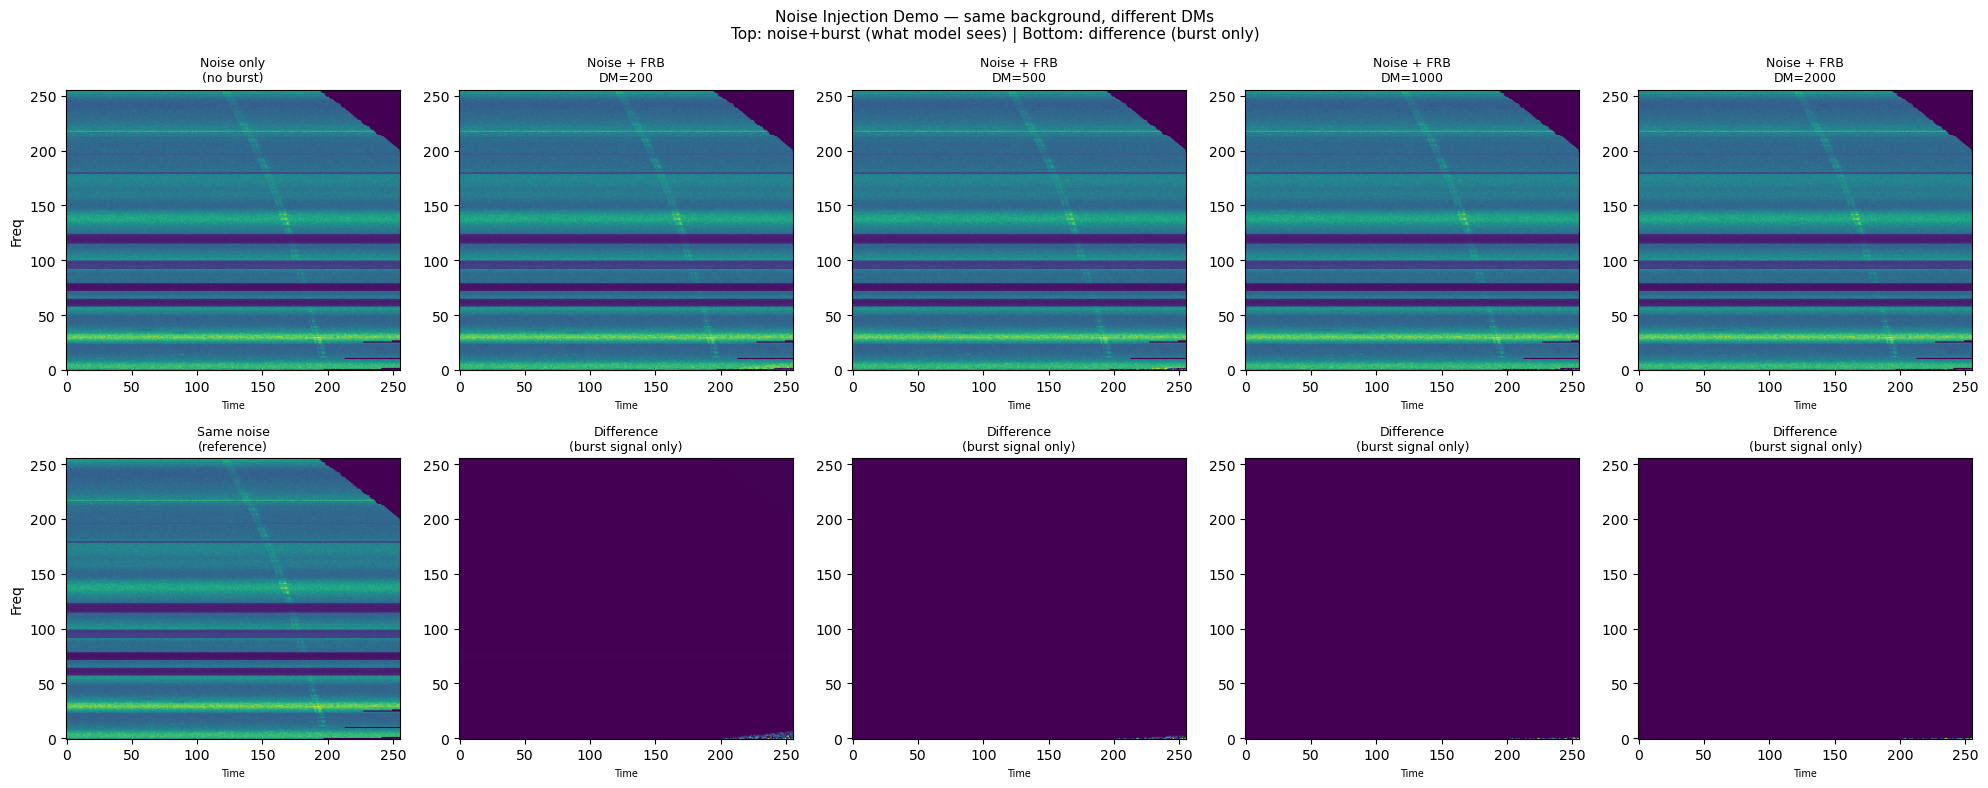

In [11]:
# Quick demo: same noise background, with and without burst injection
demo_fname = list(good_files.keys())[0]
demo_info = file_info[demo_fname]
demo_bi = burst_info[demo_fname]

demo_raw = load_spectrogram(demo_info["path"], demo_info["power_key"])
demo_ds = downsample_time(demo_raw, TIME_DOWNSAMPLE)
demo_cropped = crop_to_live_channels(demo_ds, demo_info["live_indices"])

# Pick a noise background
demo_noise = all_noise_raw[0]

demo_dms = [200, 500, 1000, 2000]
fig, axes = plt.subplots(2, len(demo_dms) + 1, figsize=(4 * (len(demo_dms) + 1), 8))

# First column: noise only
noise_norm = normalize_patch(demo_noise.copy())
axes[0, 0].imshow(noise_norm.T, aspect='auto', origin='lower', cmap='viridis')
axes[0, 0].set_title("Noise only\n(no burst)", fontsize=9)
axes[0, 0].set_ylabel("Freq")
axes[1, 0].imshow(noise_norm.T, aspect='auto', origin='lower', cmap='viridis')
axes[1, 0].set_title("Same noise\n(reference)", fontsize=9)
axes[1, 0].set_ylabel("Freq")

# Other columns: noise + injected burst at different DMs
for col, dm in enumerate(demo_dms):
    injected = make_injected_frb_patch(
        demo_cropped, demo_bi["peak_idx"], demo_bi["burst_width"],
        dm, 0.3, demo_noise.copy()
    )
    if injected is not None:
        axes[0, col + 1].imshow(injected.T, aspect='auto', origin='lower', cmap='viridis')
        axes[0, col + 1].set_title(f"Noise + FRB\nDM={dm}", fontsize=9)
        
        # Difference: injected minus noise-only
        diff = injected - noise_norm
        axes[1, col + 1].imshow(diff.T, aspect='auto', origin='lower', cmap='viridis')
        axes[1, col + 1].set_title(f"Difference\n(burst signal only)", fontsize=9)

for ax in axes.flatten():
    ax.set_xlabel("Time", fontsize=7)

plt.suptitle(f"Noise Injection Demo — same background, different DMs\n"
             f"Top: noise+burst (what model sees) | Bottom: difference (burst only)", fontsize=11)
plt.tight_layout()
plt.show()

In [12]:
# Full FRB extraction with noise injection
all_frb = []
all_frb_meta = []

temporal_positions = np.linspace(0.1, 0.9, N_TEMPORAL_SHIFTS)

for fname, bi in good_files.items():
    info = file_info[fname]
    dm_orig = bi["dm"]
    peak = bi["peak_idx"]
    count = 0
    
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    # A) Original DM at various positions, each on a random noise background
    for pos in temporal_positions:
        noise_bg = all_noise_raw[rng.randint(len(all_noise_raw))].copy()
        patch = make_injected_frb_patch(
            cropped, peak, bi["burst_width"], dm_orig, pos, noise_bg
        )
        if patch is not None:
            all_frb.append(patch)
            all_frb_meta.append({"src": fname, "dm": dm_orig,
                                  "pos": pos, "type": "original"})
            count += 1
    
    # B) Augmented DMs on random noise backgrounds
    aug_dms = rng.uniform(DM_AUG_RANGE[0], DM_AUG_RANGE[1], N_DM_AUGMENTS)
    for new_dm in aug_dms:
        pos = rng.uniform(0.1, 0.9)
        noise_bg = all_noise_raw[rng.randint(len(all_noise_raw))].copy()
        patch = make_injected_frb_patch(
            cropped, peak, bi["burst_width"], new_dm, pos, noise_bg
        )
        if patch is not None:
            all_frb.append(patch)
            all_frb_meta.append({"src": fname, "dm": float(new_dm),
                                  "pos": pos, "type": "dm_aug"})
            count += 1
    
    print(f"{fname[:52]:52s}: {count:>3d} FRB patches")

print(f"\nTotal FRB patches: {len(all_frb)}")
print(f"  Original DM: {sum(1 for m in all_frb_meta if m['type'] == 'original')}")
print(f"  DM-augmented: {sum(1 for m in all_frb_meta if m['type'] == 'dm_aug')}")

FRB20181209A_22154974_beamformed.h5                 :  38 FRB patches
FRB20181213A_22310619_beamformed.h5                 :  38 FRB patches
FRB20181226E_23948798_beamformed.h5                 :  38 FRB patches
FRB20181231A_24342210_beamformed.h5                 :  38 FRB patches
FRB20181231C_24366209_beamformed.h5                 :   0 FRB patches
FRB20190102A_24510924_beamformed.h5                 :  38 FRB patches
FRB20190103C_24644651_beamformed.h5                 :  38 FRB patches
FRB20190210B_30105124_beamformed.h5                 :  38 FRB patches
FRB20190213D_30502098_beamformed.h5                 :  38 FRB patches
FRB20190227A_31938812_beamformed.h5                 :  38 FRB patches
FRB20190304B_32415255_beamformed.h5                 :  38 FRB patches
FRB20190405B_35579228_beamformed.h5                 :  38 FRB patches
FRB20190420B_37342401_beamformed.h5                 :  38 FRB patches
FRB20190423A_37637444_beamformed.h5                 :  38 FRB patches
FRB20190425B_3794819

## 6. Normalize Noise Patches & Visualize

In [13]:
# Normalize noise patches (FRB patches were already normalized during injection)
all_noise = [normalize_patch(p) for p in all_noise_raw]
print(f"Noise patches normalized: {len(all_noise)}")

Noise patches normalized: 5


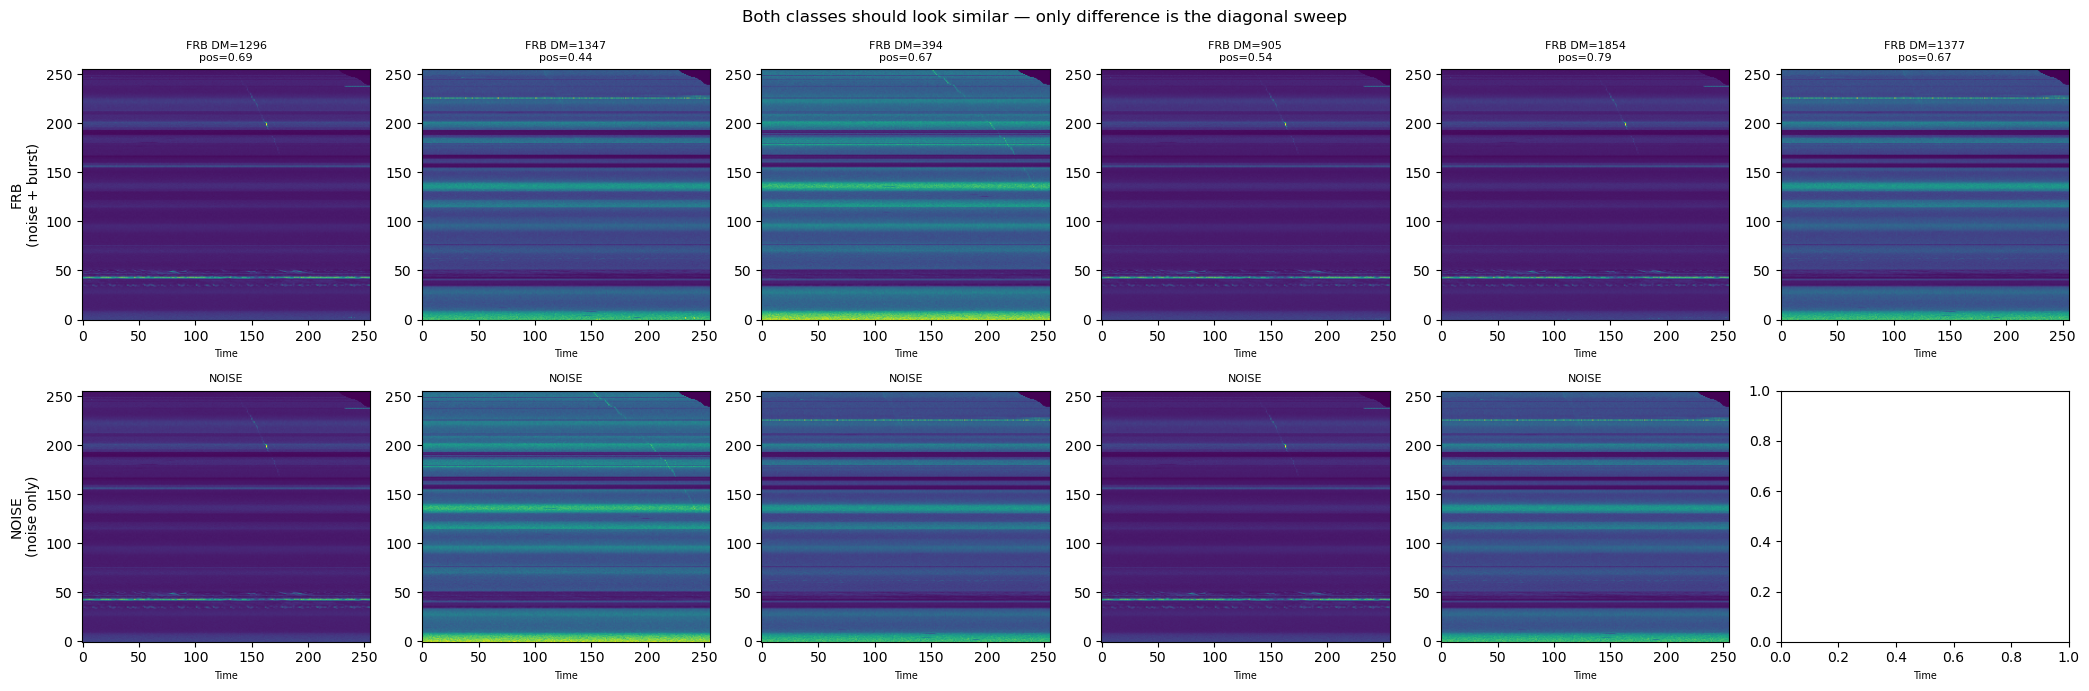

In [14]:
n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(3.5 * n_show, 7))

# Top: FRB (noise + injected burst)
for col in range(min(n_show, len(all_frb))):
    idx = rng.randint(len(all_frb))
    axes[0, col].imshow(all_frb[idx].T, aspect='auto', origin='lower', cmap='viridis')
    m = all_frb_meta[idx]
    axes[0, col].set_title(f"FRB DM={m['dm']:.0f}\npos={m['pos']:.2f}", fontsize=8)

# Bottom: Noise only
for col in range(min(n_show, len(all_noise))):
    idx = rng.randint(len(all_noise))
    axes[1, col].imshow(all_noise[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[1, col].set_title("NOISE", fontsize=8)

axes[0, 0].set_ylabel("FRB\n(noise + burst)")
axes[1, 0].set_ylabel("NOISE\n(noise only)")

for ax in axes.flatten():
    ax.set_xlabel("Time", fontsize=7)

plt.suptitle("Both classes should look similar — only difference is the diagonal sweep", fontsize=12)
plt.tight_layout()
plt.show()

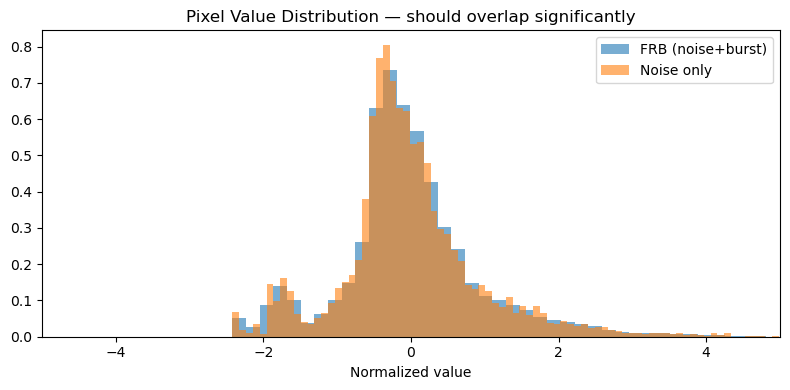

In [15]:
# Check pixel distributions — should now overlap much more
fig, ax = plt.subplots(figsize=(8, 4))

frb_sample = np.array(all_frb[:200]).flatten()[::50]
noise_sample = np.array(all_noise[:200]).flatten()[::50]

ax.hist(frb_sample, bins=100, alpha=0.6, label='FRB (noise+burst)', density=True)
ax.hist(noise_sample, bins=100, alpha=0.6, label='Noise only', density=True)
ax.set_xlim(-5, 5)
ax.set_title("Pixel Value Distribution — should overlap significantly")
ax.set_xlabel("Normalized value")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Balance, Split & Save

In [16]:
n_frb = len(all_frb)
n_noise = len(all_noise)
print(f"Raw counts: {n_frb} FRB, {n_noise} noise")

# NOTE: capturing the exact indices rng.choice() returns (instead of consuming
# them inline in a list comprehension, as before) so we can pull the matching
# DM value for each selected FRB patch from all_frb_meta. This does not add or
# change any random draws -- same calls, same counts, same results -- so
# frb_patches/noise_patches/X_train/X_val/X_test come out byte-identical to
# the original run.

if n_frb < n_noise * 0.5:
    print(f"FRB minority → oversampling FRB")
    noise_patches = all_noise
    frb_idx = rng.choice(n_frb, n_noise, replace=True)
    frb_patches = [all_frb[i] for i in frb_idx]
elif n_noise < n_frb * 0.5:
    print(f"Noise minority → oversampling noise")
    frb_idx = np.arange(n_frb)
    frb_patches = all_frb
    noise_patches = [all_noise[i] for i in rng.choice(n_noise, n_frb, replace=True)]
else:
    target = min(n_frb, n_noise)
    frb_idx = rng.choice(n_frb, target, replace=False)
    frb_patches = [all_frb[i] for i in frb_idx]
    noise_patches = [all_noise[i] for i in rng.choice(n_noise, target, replace=False)]

frb_dm_values = np.array([all_frb_meta[i]["dm"] for i in frb_idx], dtype=np.float32)

print(f"Balanced: {len(frb_patches)} FRB, {len(noise_patches)} noise")
print(f"DM values captured for {len(frb_dm_values)} FRB patches "
      f"(range {frb_dm_values.min():.0f}-{frb_dm_values.max():.0f} pc/cm3)")

Raw counts: 1026 FRB, 5 noise
Noise minority → oversampling noise
Balanced: 1026 FRB, 1026 noise
DM values captured for 1026 FRB patches (range 100-2496 pc/cm3)


In [17]:
from sklearn.model_selection import train_test_split

X = np.concatenate([
    np.array(frb_patches, dtype=np.float32),
    np.array(noise_patches, dtype=np.float32)
], axis=0)
y = np.concatenate([
    np.ones(len(frb_patches), dtype=np.float32),
    np.zeros(len(noise_patches), dtype=np.float32)
])
# Noise patches have no burst DM -> NaN sentinel. Order matches X's
# concatenation order (frb_patches first, then noise_patches) exactly.
dm_full = np.concatenate([
    frb_dm_values,
    np.full(len(noise_patches), np.nan, dtype=np.float32)
])

shuf = rng.permutation(len(X))
X, y, dm_full = X[shuf], y[shuf], dm_full[shuf]

X_train, X_temp, y_train, y_temp, dm_train, dm_temp = train_test_split(
    X, y, dm_full, test_size=0.3, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test, dm_val, dm_test = train_test_split(
    X_temp, y_temp, dm_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

print(f"Final: {X.shape}")
print(f"Train: {X_train.shape[0]:>5d} ({np.mean(y_train):.1%} FRB)")
print(f"Val:   {X_val.shape[0]:>5d} ({np.mean(y_val):.1%} FRB)")
print(f"Test:  {X_test.shape[0]:>5d} ({np.mean(y_test):.1%} FRB)")
print(f"DM values present for {np.sum(~np.isnan(dm_test))}/{len(dm_test)} test examples "
      f"(should equal the FRB count in the test split)")

Final: (2052, 256, 256)
Train:  1436 (50.0% FRB)
Val:     308 (50.0% FRB)
Test:    308 (50.0% FRB)
DM values present for 154/308 test examples (should equal the FRB count in the test split)


In [18]:
save_path = os.path.join(OUTPUT_DIR, "lstm_dataset_v6.npz")
np.savez_compressed(
    save_path,
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    dm_train=dm_train, dm_val=dm_val, dm_test=dm_test,
)
fsize_mb = os.path.getsize(save_path) / 1e6
print(f"Saved: {save_path} ({fsize_mb:.1f} MB)")
print("Now includes dm_train/dm_val/dm_test (NaN for noise examples).")

Saved: ./augmented_dataset/lstm_dataset_v6.npz (495.5 MB)
Now includes dm_train/dm_val/dm_test (NaN for noise examples).


## 8. Final Quality Report

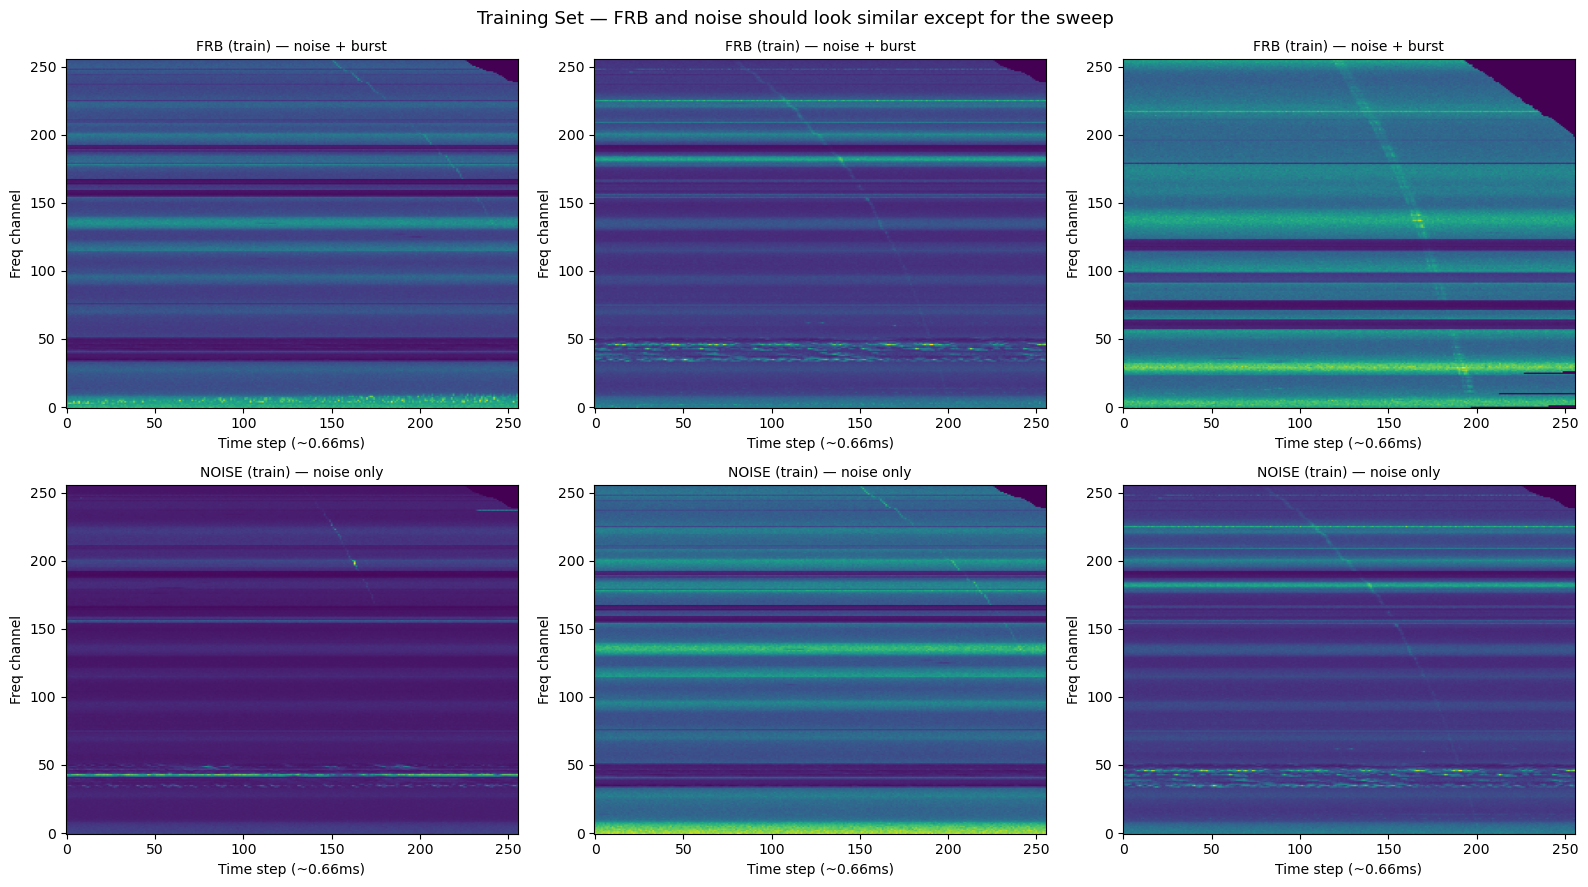

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

frb_idx = np.where(y_train == 1)[0]
noise_idx = np.where(y_train == 0)[0]

for col in range(3):
    idx = frb_idx[rng.randint(len(frb_idx))]
    axes[0, col].imshow(X_train[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[0, col].set_title(f"FRB (train) — noise + burst", fontsize=10)
    axes[0, col].set_xlabel("Time step (~0.66ms)")
    axes[0, col].set_ylabel("Freq channel")

for col in range(3):
    idx = noise_idx[rng.randint(len(noise_idx))]
    axes[1, col].imshow(X_train[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[1, col].set_title(f"NOISE (train) — noise only", fontsize=10)
    axes[1, col].set_xlabel("Time step (~0.66ms)")
    axes[1, col].set_ylabel("Freq channel")

plt.suptitle("Training Set — FRB and noise should look similar except for the sweep", fontsize=13)
plt.tight_layout()
plt.show()

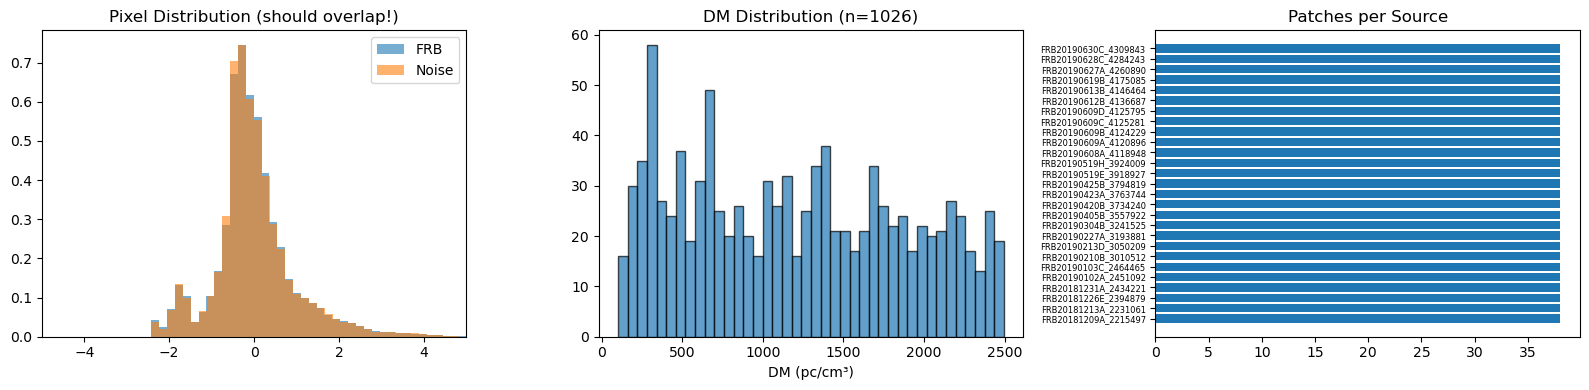


DATASET SUMMARY
Total samples:       2052
LSTM input shape:    (batch, 256, 256)
Train/Val/Test:      1436/308/308
Class balance:       50.0% FRB / 50.0% noise
Source FRBs:         29 unique bursts
DM range:            100 – 2496 pc/cm³
SNR injection range: (0.5, 5.0)
Pipeline:            load → DS ×256 → crop → redisperse → inject onto noise → normalize
Saved to:            ./augmented_dataset/lstm_dataset_v6.npz

Update LSTM notebook: data_path → './augmented_dataset/lstm_dataset_v6.npz'


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

frb_vals = X_train[y_train == 1].flatten()[::50]
noise_vals = X_train[y_train == 0].flatten()[::50]
axes[0].hist(frb_vals, bins=100, alpha=0.6, label='FRB', density=True)
axes[0].hist(noise_vals, bins=100, alpha=0.6, label='Noise', density=True)
axes[0].set_xlim(-5, 5)
axes[0].set_title("Pixel Distribution (should overlap!)")
axes[0].legend()

aug_dms = [m["dm"] for m in all_frb_meta]
axes[1].hist(aug_dms, bins=40, edgecolor='black', alpha=0.7)
axes[1].set_title(f"DM Distribution (n={len(aug_dms)})")
axes[1].set_xlabel("DM (pc/cm³)")

from collections import Counter
src_counts = Counter(m["src"][:20] for m in all_frb_meta)
axes[2].barh(range(len(src_counts)), list(src_counts.values()))
axes[2].set_yticks(range(len(src_counts)))
axes[2].set_yticklabels(list(src_counts.keys()), fontsize=6)
axes[2].set_title("Patches per Source")

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"Total samples:       {len(X)}")
print(f"LSTM input shape:    (batch, {PATCH_TIME_BINS}, {TARGET_FREQ_BINS})")
print(f"Train/Val/Test:      {len(X_train)}/{len(X_val)}/{len(X_test)}")
print(f"Class balance:       {np.mean(y):.1%} FRB / {1-np.mean(y):.1%} noise")
print(f"Source FRBs:         {len(good_files)} unique bursts")
print(f"DM range:            {min(aug_dms):.0f} – {max(aug_dms):.0f} pc/cm³")
print(f"SNR injection range: {SNR_INJECT_RANGE}")
print(f"Pipeline:            load → DS ×{TIME_DOWNSAMPLE} → crop → redisperse → inject onto noise → normalize")
print(f"Saved to:            {save_path}")
print(f"\nUpdate LSTM notebook: data_path → '{save_path}'")